In [1]:
import numpy as np
from functools import partial

import jax.numpy as jnp
import jax.scipy.special as jss
import jax

from tensorflow_probability.substrates import jax as tfp
tfd = tfp.distributions

from jax.config import config
config.update("jax_enable_x64", True)

import bridgestan as bs
bs.set_bridgestan_path('/Users/meenaljhajharia/github/rouldes/bridgestan')

In [2]:
N =  10
alpha = jnp.asarray([1]*10)

stan = "../transforms/simplex/ALR.stan"
data = "data.json"

model = bs.StanModel.from_stan_file(stan, data)
x = np.random.random(model.param_unc_num())
y = np.log(x / (1 - x))  # unconstrained scale 


### Bridgestan

In [3]:
lp, grad, hessian = model.log_density_hessian(y)
print('hessian:', jnp.linalg.cond(hessian), '\n\n eigenvalues:', jnp.linalg.eig(hessian)[0])

hessian: 91.2821242560352 

 eigenvalues: [-2.84407378+0.j -0.90836365+0.j -0.81849352+0.j -0.64983404+0.j
 -0.40442433+0.j -0.03115696+0.j -0.07983875+0.j -0.22028059+0.j
 -0.16538689+0.j]


### Jax

In [13]:
@partial(jax.jit, static_argnames=['N'])
def stan_transform(y, N):
    log_det_jacobian = jnp.sum(jnp.sum(y) - N*jss.logsumexp(jnp.append(y,values=0)) + 0.5*jnp.log(N))
    L = jax.nn.softmax(jnp.append(y,values=0))
    return L, log_det_jacobian

@partial(jax.jit, static_argnames=['N'])
def lp_stan(y, alpha, N):
    L, log_det_jacobian = stan_transform(y, N)
    return log_det_jacobian + tfd.Dirichlet(alpha.astype(jnp.float64)).log_prob(L)

hessian = jax.hessian(lp_stan)(y, alpha, N)
print('hessian condition number:', jnp.linalg.cond(hessian), '\n\n eigenvalues:', jnp.linalg.eig(hessian)[0])

hessian condition number: 91.28212419352411 

 eigenvalues: [-2.84407378+0.j -0.90836365+0.j -0.81849352+0.j -0.64983404+0.j
 -0.40442433+0.j -0.03115696+0.j -0.07983875+0.j -0.22028059+0.j
 -0.16538689+0.j]


In [12]:
model = bs.StanModel.from_stan_file("../transforms/simplex/HypersphericalAngular.stan", data)
lp, grad, hessian = model.log_density_hessian(y)
print('hessian condition number:', jnp.linalg.cond(hessian), '\n\n eigenvalues:', jnp.linalg.eig(hessian)[0])

hessian condition number: 14.515921325882148 

 eigenvalues: [-3.50215011+0.j -3.66975639+0.j -3.92946456+0.j -3.96009217+0.j
 -0.27281025+0.j -1.95929911+0.j -2.05730244+0.j -0.9065704 +0.j
 -1.11449309+0.j]


In [11]:
model = bs.StanModel.from_stan_file("../transforms/simplex/Stickbreaking.stan", data)
lp, grad, hessian = model.log_density_hessian(y)
print('hessian condition number:', jnp.linalg.cond(hessian), '\n\n eigenvalues:', jnp.linalg.eig(hessian)[0])

hessian condition number: 7.10537018654882 

 eigenvalues: [-1.83669035+0.j -0.25849327+0.j -0.47061957+0.j -0.54454326+0.j
 -1.59913307+0.j -1.31048423+0.j -1.04017054+0.j -1.19393678+0.j
 -0.49918431+0.j]


In [59]:
model = bs.StanModel.from_stan_file("../transforms/simplex/HypersphericalLogit.stan", data)
lp, grad, hessian = model.log_density_hessian(y)
print('hessian condition number:', jnp.linalg.cond(hessian), '\n\n eigenvalues:', jnp.linalg.eig(hessian)[0])

hessian condition number: 1.0000154694754837 

 eigenvalues: [-0.49892595+0.j -0.49892499+0.j -0.49892402+0.j -0.49892306+0.j
 -0.49892209+0.j -0.49892113+0.j -0.49892016+0.j -0.4989192 +0.j
 -0.49891823+0.j]


In [67]:
eigenvalues=jnp.abs(jnp.linalg.eig(hessian)[0])

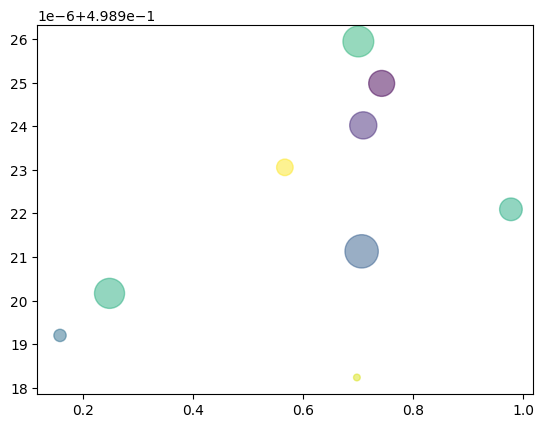

In [69]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(19680801)

N = 9
y = np.random.rand(N)
colors = np.random.rand(N)
area = (30 * np.random.rand(N))**2

plt.scatter(y,eigenvalues, s=area, c=colors, alpha=0.5)
plt.show()